In [ ]:
#Libraries
!pip install ultralytics #installing the ultralytics library for yolo
from ultralytics import YOLO #importing yolo from ultralytics library

import tensorflow as tf
from tensorflow.keras import datasets, layers, models #building CNN
import matplotlib.pyplot as plt


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 100.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 75.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 47.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 61.4 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling

In [ ]:
from google.colab import drive
# it will link to your google drive and may ask you to go through a verification step
drive.mount('/content/drive')

Mounted at /content/drive


# **Obtaining the Dataset**

In [ ]:
import numpy as np
import pandas as pd
import cv2

# define the path to your images and labels
dataset_path = '/content/drive/MyDrive/Images/Resistor_Dataset/archive.zip (Unzipped Files)/'
csv_label_path = dataset_path+'smallResistorCSV5.csv'


# read the CSV file
df = pd.read_csv(csv_label_path, header=None)

# rename the columns for better understanding
df.columns = ['Image_name', 'Band_Qnt', 'Resistance','Tolerance','Watts','Bands','Usage','Object_type']

# select the training samples from the dataset
train_df = df[df['Usage'] == 'TRAIN']

# compute the number of training samples
mun_train = train_df.shape[0]

# create empty arrays to store images and labels for training
train_labels = np.empty([mun_train, 1], dtype=np.float32)
train_images = np.empty([mun_train, 256,256,3], dtype=np.float32)

# building the training image and label tensors
for i in range(mun_train):
  train_name = train_df.iloc[i, 0] #locating the img name within the 0 column of the CSV
  train_path = dataset_path + train_name  #adding it to the dataset path to form directory to img
  img = tf.keras.utils.load_img(train_path) #loading the img via tensor flow keras
  img = tf.keras.utils.load_img(train_path, target_size=(256, 256))  #setting the img size
  img_array = tf.keras.utils.img_to_array(img)#convertin the image to its array
  train_images[i] = img_array #storing img in train imgs
  train_labels[i] = train_df.iloc[i, 7] #storing the label of the img accessed from CSV column 7

# select the testing samples from the dataset
test_df = df[df['Usage'] == 'TEST']

#making a copy of the dataframe to keep any potential modifications seperate
test_bands_df= test_df.copy()

# compute the number of testing samples
mun_test = test_df.shape[0]

# create empty arrays to store images and labels for testing
test_labels = np.empty([mun_test, 1], dtype=np.float32)
test_images = np.empty([mun_test, 256,256,3], dtype=np.float32)

# building the testing image and label tensors, same process as train
for i in range(mun_test):
  test_name = test_df.iloc[i, 0]#locating the img name within the 0 column of the CSV
  test_path = dataset_path + test_name #adding it to the dataset path to form directory to img
  img = tf.keras.utils.load_img(test_path)#loading the img via tensor flow keras
  img = tf.keras.utils.load_img(test_path, target_size=(256, 256))  #setting the img size
  img_array = tf.keras.utils.img_to_array(img)#convertin the image to its array
  test_images[i] = img_array #storing img in test imgs
  test_labels[i] = test_df.iloc[i, 7] #storing is label accessed via CSV column 7

#Normalising pixel values from 0-255 to floats between 0-1
train_images = train_images / 255.0  # Assuming they are float and in range [0, 255]
test_images = test_images / 255.0  # Assuming they are float and in range [0, 255]


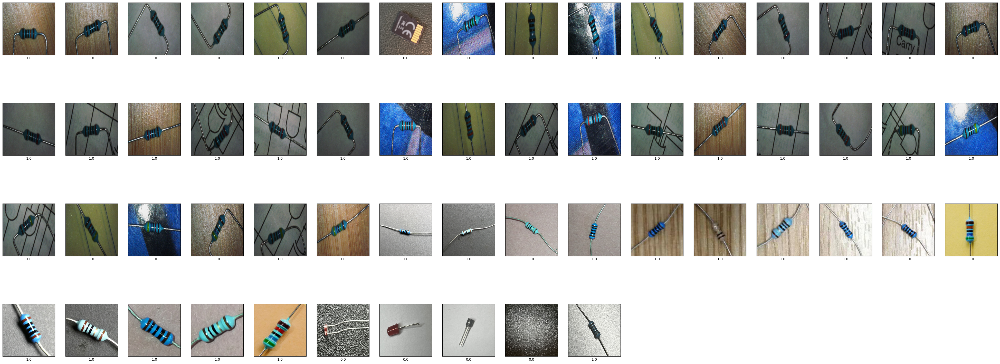

In [ ]:
#ensuring the test images have been correctly accessed and stored
plt.figure(figsize=(50,50))
for i in range(mun_test):
    plt.subplot(10,16,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(test_images[i], cmap=plt.cm.binary)
    plt.xlabel(test_labels[i][0])

plt.show()

# **Building the Model**

In [ ]:
model = models.Sequential()#sequential structure

#following VGG format
#Covolution and pooling layers
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(256, 256, 3)))#256x256 image
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Conv2D(128, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))



/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.add(layers.Flatten())#flattening
model.add(layers.Dense(64, activation='relu'))#dense layer kernel size
model.add(layers.Dense(2))#two classes (0) or (1)

In [ ]:
model.summary() #evaluating model structure

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,605,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,736,002 (6.62 MB)

 Trainable params: 1,736,002 (6.62 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#compiling and fitting the model to measure accuracy
model.compile(optimizer='adam', #optimiser = adam
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), #loss function comapring true and predicted values
              metrics=['accuracy']) # want to measure accuracy

history = model.fit(train_images, train_labels, epochs=6, #fitting the model with train images and performing 6 epochs
                    validation_data=(test_images, test_labels)) #validating with test images

Epoch 1/6
12/12 ━━━━━━━━━━━━━━━━━━━━ 53s 4s/step - accuracy: 0.7979 - loss: 0.6171 - val_accuracy: 0.9138 - val_loss: 0.4223
Epoch 2/6
12/12 ━━━━━━━━━━━━━━━━━━━━ 79s 4s/step - accuracy: 0.8623 - loss: 0.4030 - val_accuracy: 0.9138 - val_loss: 0.4008
Epoch 3/6
12/12 ━━━━━━━━━━━━━━━━━━━━ 86s 4s/step - accuracy: 0.8791 - loss: 0.2182 - val_accuracy: 0.9138 - val_loss: 0.1232
Epoch 4/6
12/12 ━━━━━━━━━━━━━━━━━━━━ 76s 4s/step - accuracy: 0.9367 - loss: 0.1129 - val_accuracy: 0.9483 - val_loss: 0.1182
Epoch 5/6
12/12 ━━━━━━━━━━━━━━━━━━━━ 47s 4s/step - accuracy: 0.9866 - loss: 0.0906 - val_accuracy: 0.9655 - val_loss: 0.0987
Epoch 6/6
12/12 ━━━━━━━━━━━━━━━━━━━━ 82s 4s/step - accuracy: 0.9935 - loss: 0.0685 - val_accuracy: 0.9310 - val_loss: 0.0997


2/2 - 2s - 939ms/step - accuracy: 0.9310 - loss: 0.0997


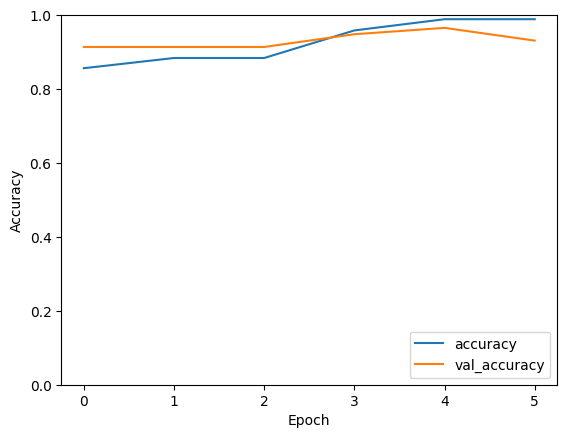

In [ ]:
#Plotting the CNN'S results
plt.plot(history.history['accuracy'], label='accuracy') #plotting the accuracy
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')#and validation accuracy
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1]) #0-1 1 = 100%
plt.legend(loc='lower right')

test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2) #testing the model on unseen data

In [ ]:
print(test_acc) #outputted accuracy

0.931034505367279


# **Training Results**

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 244ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step

1/1 ━━━━━━━━━━━━━

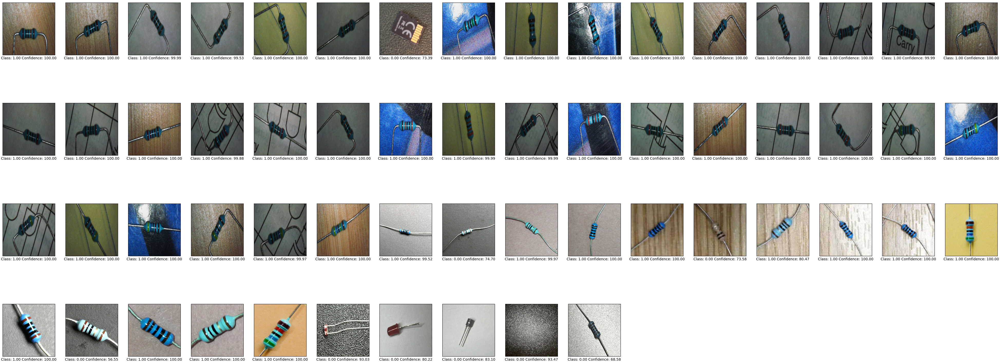

In [ ]:
plt.figure(figsize=(50,50))

for i in range(mun_test):
  x = test_images[i];

  x = np.reshape(x,(1,256,256,3)) #batch,length, width, colour channels
  category = model.predict(x) #model.predict returns a matrix of the weight of how much it thinks something is
  print() #argmax
  score = tf.nn.softmax(category[0]) #finds its confidence rating of its classification
  plt.subplot(10,16,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(test_images[i], cmap=plt.cm.binary) #showing the results
  plt.xlabel("Class: {:.2f} Confidence: {:.2f}" #featuring its class and confidence that it belongs to the class
.format(category.argmax(), 100 * np.max(score)))
plt.show()

# **Band Identification and Calculation**

In [ ]:
#Used to calculate the resistance based off the band colours and positioning
def calculate_ohms(bands):
  qnty_bands = len(bands) #getting the amount of bands
  print("Quantity of Bands{}"
      .format(qnty_bands))
  ohms = 0.0
  tolerance = 0

  if qnty_bands ==4:     #finding the multiplier band dependant on resistor band qnty
    multiplier_index =2
  elif qnty_bands == 5:
      multiplier_index =3
  else:
    print("Band Readings Incorrect") #only working for 4-5 band resistors
    return ohms,qnty_bands,tolerance

  Colour_mapping={  #regular band mapping
      'Black':0,
      'Brown':1,
      'Red':2,
      'Orange':3,
      'Yellow':4,
      'Green':5,
      'Blue':6,
      'Violet':7,
      'Grey':8,
      'White':9

  }
  Colour_mapping_multiplier={ #multipliers band mapping
      'Black':1,
      'Brown':10,
      'Red':100,
      'Orange':1000,
      'Yellow':10000,
      'Green':100000,
      'Blue':1000000,
      'Violet':10000000,
      'Gold':0.1,
      'Silver':0.01,
      'Grey':1,
      'White':1
  }

  Colour_mapping_tolerance={ #tolerance band mapping
      'Black':0,
      'Brown':1,
      'Red':2,
      'Orange':0,
      'Yellow':0,
      'Green':0.5,
      'Blue':0.25,
      'Violet':0.10,
      'Gold':5,
      'Silver':10,
      'Grey':0.05,
      'White':0
  }


  if bands[0] in ['Gold', 'Silver'] or bands[1] in ['Gold', 'Silver']:#checking if its the wrong way round
      bands = bands[::-1] #invering the band list

  for i in range(multiplier_index): #for all the regular bands
    resistance = Colour_mapping[bands[i]] #find the band colours value
    ohms = ohms * 10 + resistance  #add it to the total ohms
    print("Band Colour: {}, Band Value: {}"
      .format(bands[i],resistance))

  ohms = ohms*Colour_mapping_multiplier[bands[multiplier_index]] #find the multiplier bands value and multiply the ohms
  print("Band Multiplier Colour: {}, Band Multiplier Value: {}"
      .format(bands[(multiplier_index)],(Colour_mapping_multiplier[bands[multiplier_index]])))

  tolerance = Colour_mapping_tolerance[bands[qnty_bands-1]] #find the tolerance bands value
  print("Band Tolerance Colour: {}, Band Tolerance Value: {}"
      .format((bands[qnty_bands-1]),(tolerance)))

  return ohms,qnty_bands,tolerance

In [ ]:
#Finding and categorising the bands using Yolo v11
def band_finder(model_path,test_img):
  band_colours = []

  yolo_model = YOLO(model_path) #setting up the model
  results = yolo_model.predict(test_img, save=True)#inputing the testimg in to get the band values

  for result in results: #accessing the results
    boxes = result.boxes  # getting the bounding boxes

    for box in boxes: #for each of the bounding boxes
      class_id = int(box.cls[:10])  # getting the Class index as integer
      class_name = yolo_model.names[class_id]  #Getting the class name

      box_coord = box.xyxy[0].numpy()  # Getting the coordinates of the bounding box edges
      center_x = (box_coord[0] + box_coord[2]) / 2  # Center of the bounding box

      band_colours.append((center_x, class_name))  # Saving pos and class as a tupple allowing us to sort

    band_colours.sort(key=lambda x: x[0])  # Sorting bands by first element in tupple, x position (left to right)

    band_colours = [item[1] for item in band_colours]#band names left to right

    ohms,qnty_bands,tolerance = calculate_ohms(band_colours) #calculate the bands values and resistor (now in order)
    img_array = result.plot()  # Returning as numpy arr

  return img_array,ohms,qnty_bands,tolerance

# **Resistor Identification**

In [ ]:
#Using our VGG CNN to determine if resistor is present
def resistor_recognition(img,test_img):
  img = tf.keras.utils.load_img(test_img, target_size=(256, 256))  #setting the img size to 32x32 to fix the resolution

  img_array = tf.keras.utils.img_to_array(img)#convertin the image to its array
  img_array = tf.expand_dims(img_array, 0) /255 #creating batch for predict() function and normalising it

  predictions = model.predict(img_array) #predicting what
  score = tf.nn.softmax(predictions[0]) #finds its confidence rating of its classification

  return score

# **Implementing the CNN and YOLO to form the algorithm**

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step

0: 384x640 1 Black, 1 Brown, 1 Gold, 1 Yellow, 519.0ms
Speed: 31.5ms preprocess, 519.0ms inference, 34.6ms postprocess per image at shape (1, 3, 384, 640)
Results saved to runs/detect/predict
Quantity of Bands4
Band Colour: Brown, Band Value: 1
Band Colour: Black, Band Value: 0
Band Multiplier Colour: Yellow, Band Multiplier Value: 10000
Band Tolerance Colour: Gold, Band Tolerance Value: 5


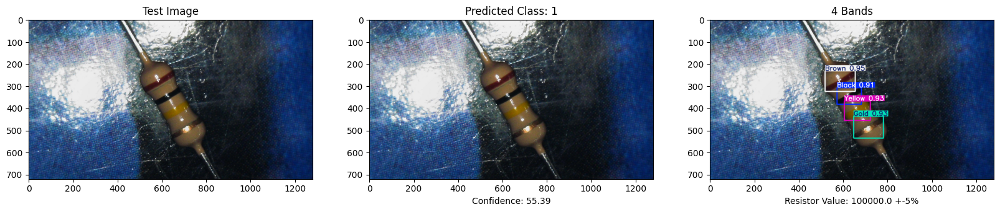

In [ ]:
test_img = "/content/drive/MyDrive/Images/Resistor_Dataset/dataset/4B-100K-T5-4.jpg"
model_path = "/content/drive/MyDrive/YoloModel/model2/my_model2/train/weights/best.pt"
plt.figure(figsize=(20,20))

img = tf.keras.utils.load_img(test_img) #loading in image via keras for CNN

#displaying original image
plt.subplot(2,3,1)
plt.title("Test Image")
plt.imshow(img)

score=resistor_recognition(img,test_img) #searching for if there is a resistor

#if np.argmax(score)==1: #can be used to only scan for bands IF a resistor is present

img_array,ohms,bands,tolerance=band_finder(model_path,img) #find the bands and calculate the ohms
img_array = cv2.cvtColor(img_array, cv2.COLOR_BGR2RGB) #convert back to RGB as yolo returns BGR

#displaying resistor bands found and resistance value calculated
plt.subplot(2,3,3)
plt.imshow(img_array)
plt.title("{} Bands"
.format(bands))
plt.xlabel("Resistor Value: {} +-{}%"
.format(ohms,tolerance))

#else:         #If no resistors are present
 # print("No Resistor Present In Image, Please get closer or improve image quality") #if there is no resistor send error message

#display the original image with the classification result (resistor or no resistor)
plt.subplot(2,3,2)
plt.title("Predicted Class: {}"
.format(np.argmax(score)))
plt.xlabel("Confidence: {:.2f}"
.format(100 * np.max(score)))
plt.imshow(img)

